# 07 — Report figures (model runs on the test set)

Makes the report figures that need the trained models and test images. Uses the checkpoints already in `models/`
and the official val split (= our test set). No training. Everything goes to `results/figures/report/`.

| Report fig | File | Needs |
|---|---|---|
| 3.1 | `fig_dataset_grid_25.png` | 25 test images |
| 3.3 | `fig_defect_area_hist.png` | full test pass |
| 3.5 | `fig_dataset_samples.png` | 4 test images + cause sentences |
| 3.6 | `fig_augmentation_examples.png` | 1 image |
| 4.6 | `fig_attribute_extraction.png` | si_91.jpg |
| 5.2 | `fig_confusion_matrix.png` | full test pass |
| 5.4 | `fig_unknown_threshold_curve.png` | internal-val pass (806 train images) |
| 5.8 | `fig_image_iou_hist.png` | full test pass |
| 5.11 | `fig_seg_failures.png` | full test pass |
| 5.12 | `fig_pixel_roc_pr.png` | full test pass |
| 5.15 | `fig_uncertainty_vs_error.png` | MC-Dropout subset |
| 5.16 | `fig_confidence_vs_iou.png` | MC-Dropout subset |
| 5.19 | `fig_worked_example.png` | si_91.jpg |

**Runtime.** The three passes are cached in `results/figures/report/cache/`, so a re-run only redraws figures.
First run downloads about 5,500 small images from Hugging Face one at a time (same as notebook 06) and runs
U-Net, DeepLabV3+ and the classifier on all 2,324 test images, plus 30 MC-Dropout passes on a stratified subset.
Expect roughly 30–60 minutes on a laptop CPU (the MC-Dropout pass is about 3 s per image), less on an
Apple-silicon GPU (`mps`, picked automatically) or CUDA. To speed it up, set
`SDX_DATA_ROOT` to a local clone of the dataset, or lower `N_MC_PER_CLASS`.

In [1]:
import os, sys, json, random, textwrap
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook opened from notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from tqdm.auto import tqdm
from src.segmentation.model import build_model, enable_mc_dropout
from src.segmentation.classifier import build_classifier
from src.config import REVIEW_CONFIDENCE_THRESHOLD

DATA_ROOT = os.environ.get("SDX_DATA_ROOT")      # local dataset clone, or None -> download from HF
REPO_ID = "Zhaosxian/SteelDefectX"
OUT = ROOT / "results" / "figures" / "report"; OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "cache"; CACHE.mkdir(exist_ok=True)
N_MC_PER_CLASS = 16          # test images per class for the MC-Dropout figures (5.15, 5.16)
MC_PASSES = 30               # same as notebook 03 and the dashboard
LIMIT_PER_CLASS = int(os.environ["SDX_LIMIT_PER_CLASS"]) if os.environ.get("SDX_LIMIT_PER_CLASS") else None  # debug only
WORKED_EXAMPLE = "si_91.jpg"  # the record shown on the deck's worked-example slide
SEED = 0

if torch.cuda.is_available(): device = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available(): device = "mps"
else: device = "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

CLASS_NAMES = json.load(open(ROOT / "models" / "class_names.json"))
UNKNOWN_THR = json.load(open(ROOT / "models" / "class_threshold.json"))["threshold"]
INK, ORANGE, BLUE, PAPER, GREY, SOFT = "#16202A", "#E8833A", "#3E6A8A", "#F4F3EF", "#B5BCC2", "#4A5560"
plt.rcParams.update({"font.size": 11, "axes.titlesize": 11.5, "figure.facecolor": "white",
                     "savefig.facecolor": "white", "savefig.bbox": "tight", "savefig.dpi": 200})
summary = {}
print("device:", device, "| unknown-class threshold:", round(UNKNOWN_THR, 4), "| review threshold:", REVIEW_CONFIDENCE_THRESHOLD)

/Users/debarshinimondal/Desktop/BTP/SteelDefectX/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | unknown-class threshold: 0.8698 | review threshold: 0.9


## 1. Data, models and helpers (same preprocessing as notebooks 05 and 06)

In [2]:
def _fetch(rel):
    if DATA_ROOT:
        return str(Path(DATA_ROOT) / rel)
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id=REPO_ID, filename=rel, repo_type="dataset")

def _read_gray(path, interp):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return im if im.shape == (256, 256) else cv2.resize(im, (256, 256), interpolation=interp)

def load_pair(name, split="val"):
    img = _read_gray(_fetch(f"{split}/{name}"), cv2.INTER_LINEAR)
    msk = _read_gray(_fetch(f"{split}_mask/{Path(name).stem}.png"), cv2.INTER_NEAREST)
    return img, (msk > 127).astype(np.uint8)

def load_image(name, split="train"):
    return _read_gray(_fetch(f"{split}/{name}"), cv2.INTER_LINEAR)

val_text = json.load(open(_fetch("val-text.json"), encoding="utf-8"))
test_by_class = {}
for e in val_text:
    test_by_class.setdefault(e["class_name"], []).append(e["image_name"])
name_to_class = {e["image_name"]: e["class_name"] for e in val_text}

desc_path = ROOT / "dashboard" / "class_descriptions.json"
CAUSES = json.load(open(desc_path if desc_path.exists() else _fetch("class_descriptions.json"), encoding="utf-8"))
def cause_text(cls):
    v = CAUSES[cls]
    return v if isinstance(v, str) else (v.get("cause") or v.get("description") or str(v))
print(len(val_text), "test images,", len(test_by_class), "classes")

2324 test images, 25 classes


In [3]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)[:, None, None]
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)[:, None, None]

def to_tensor(gray):
    x = np.stack([gray] * 3, 0).astype(np.float32) / 255.0
    return torch.from_numpy((x - MEAN) / STD)[None].to(device)

def load_seg(arch, ckpt, dropout=0.0):
    m = build_model(arch, "resnet34", None, dropout=dropout)
    m.load_state_dict(torch.load(ROOT / ckpt, map_location="cpu"))
    return m.to(device).eval()

unet = load_seg("unet", "models/segmentation/unet_resnet34_seed0.pt")
deeplab = load_seg("deeplabv3plus", "models/segmentation/deeplabv3plus_resnet34_seed0.pt")
unet_mc = load_seg("unet", "models/unet_dropout.pt", dropout=0.2)        # the model the dashboard runs
clf = build_classifier(len(CLASS_NAMES), pretrained=False)
clf.load_state_dict(torch.load(ROOT / "models" / "classifier.pt", map_location="cpu"))
clf = clf.to(device).eval()

@torch.no_grad()
def predict(model, gray):
    model.eval()
    return torch.sigmoid(model(to_tensor(gray)))[0, 0].float().cpu().numpy()

@torch.no_grad()
def class_probs(gray):
    # identical to src.segmentation.classifier.predict_class
    return torch.softmax(clf(to_tensor(gray)), 1)[0].float().cpu().numpy()

@torch.no_grad()
def predict_mc(gray, n=MC_PASSES):
    # n stochastic passes in one batch (dropout masks differ per batch element);
    # same confidence rule as the dashboard: mean probability over predicted-defect pixels
    enable_mc_dropout(unet_mc)
    ps = torch.sigmoid(unet_mc(to_tensor(gray).repeat(n, 1, 1, 1)))[:, 0].float().cpu().numpy()
    prob, unc = ps.mean(0), ps.std(0, ddof=1)
    conf = float(prob[prob > 0.5].mean()) if (prob > 0.5).any() else float(1 - prob.mean())
    return prob, unc, conf

def iou(prob, gt):
    p, g = prob > 0.5, gt.astype(bool)
    union = (p | g).sum()
    return 1.0 if union == 0 else float((p & g).sum() / union)

def error_overlay(img, prob, gt):
    p, g = prob > 0.5, gt.astype(bool)
    rgb = np.stack([img] * 3, -1).astype(np.float32) / 255.0 * 0.8
    for m, hexcol, a in ((p & g, PAPER, 0.55), (p & ~g, ORANGE, 0.85), (~p & g, BLUE, 0.85)):
        c = np.array([int(hexcol[i:i + 2], 16) / 255 for i in (1, 3, 5)])
        rgb[m] = (1 - a) * rgb[m] + a * c
    return rgb

def gt_outline(img, gt, color=ORANGE):
    rgb = np.stack([img] * 3, -1).astype(np.float32) / 255.0
    edge = cv2.morphologyEx(gt.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    rgb[edge] = [int(color[i:i + 2], 16) / 255 for i in (1, 3, 5)]
    return rgb

ERR_LEGEND = [Patch(facecolor=PAPER, edgecolor="#9AA4AD", label="correctly segmented"),
              Patch(facecolor=ORANGE, label="false positive"),
              Patch(facecolor=BLUE, label="missed (false negative)")]

def show(ax, im, title, kind="img"):
    if kind == "img": ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    elif kind == "mask": ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    else: ax.imshow(im)
    ax.set_title(title); ax.axis("off")

## 2. Pass A — every test image: U-Net, DeepLabV3+ and the classifier (cached)

In [4]:
cache_a = CACHE / "pass_a_test.npz"
BINS = np.linspace(0, 1, 1001)
test_names = [n for c in sorted(test_by_class) for n in sorted(test_by_class[c])[:LIMIT_PER_CLASS]]

if cache_a.exists() and set(np.load(cache_a, allow_pickle=True)["names"]) == set(test_names):
    A = dict(np.load(cache_a, allow_pickle=True))
    print("loaded cached pass A:", len(A["names"]), "images")
else:
    rows = {k: [] for k in ("names", "classes", "iou_unet", "iou_dl", "gt_area", "probs")}
    hist = {k: np.zeros(1000) for k in ("unet_pos", "unet_neg", "dl_pos", "dl_neg")}
    for nm in tqdm(test_names, desc="test set"):
        img, gt = load_pair(nm)
        pu, pd = predict(unet, img), predict(deeplab, img)
        g = gt.astype(bool)
        for key, p in (("unet", pu), ("dl", pd)):
            hist[f"{key}_pos"] += np.histogram(p[g], BINS)[0]
            hist[f"{key}_neg"] += np.histogram(p[~g], BINS)[0]
        rows["names"].append(nm); rows["classes"].append(name_to_class[nm])
        rows["iou_unet"].append(iou(pu, gt)); rows["iou_dl"].append(iou(pd, gt))
        rows["gt_area"].append(float(gt.mean())); rows["probs"].append(class_probs(img))
    A = {k: np.array(v) for k, v in rows.items()} | hist
    np.savez(cache_a, **A)
    print("pass A done:", len(test_names), "images")

cls_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
y_true = np.array([cls_idx[c] for c in A["classes"]])
y_pred = A["probs"].argmax(1); top_p = A["probs"].max(1)
summary["test_n"] = int(len(y_true))
summary["test_accuracy_pct"] = round(float((y_pred == y_true).mean() * 100), 2)
summary["unet_mean_image_iou"] = round(float(A["iou_unet"].mean() * 100), 2)
summary["deeplab_mean_image_iou"] = round(float(A["iou_dl"].mean() * 100), 2)
print(summary)

test set:   0%|          | 0/2324 [00:00<?, ?it/s]

test set:   0%|          | 1/2324 [00:00<20:28,  1.89it/s]

test set:   0%|          | 6/2324 [00:00<03:17, 11.71it/s]

test set:   0%|          | 11/2324 [00:00<01:57, 19.69it/s]

test set:   1%|          | 16/2324 [00:00<01:29, 25.85it/s]

test set:   1%|          | 21/2324 [00:00<01:15, 30.57it/s]

... (458 outputs left out)

test set: 100%|█████████▉| 2316/2324 [00:56<00:00, 41.53it/s]

test set: 100%|█████████▉| 2321/2324 [00:56<00:00, 41.54it/s]

test set: 100%|██████████| 2324/2324 [00:56<00:00, 41.21it/s]

pass A done: 2324 images
{'test_n': 2324, 'test_accuracy_pct': 97.29, 'unet_mean_image_iou': 74.08, 'deeplab_mean_image_iou': 70.06}


## 3. Pass B — internal validation, classifier only (for the threshold curve, cached)

In [5]:
from src.data.make_split import load_entries, stratified_split, write_ids
split_dir = ROOT / "data" / "splits"
if not (split_dir / "internalval_ids.txt").exists():
    # same deterministic regeneration as notebook 05 (seed 42, 15% per class)
    split_dir.mkdir(parents=True, exist_ok=True)
    items, _, _ = load_entries(Path(_fetch("train-text.json")))
    tr, iv, _ = stratified_split(items, val_frac=0.15, seed=42)
    write_ids(split_dir / "train_ids.txt", tr); write_ids(split_dir / "internalval_ids.txt", iv)
    print("internal-val split regenerated:", len(tr), "/", len(iv))
iv_ids = [l.strip() for l in (split_dir / "internalval_ids.txt").read_text(encoding="utf-8").splitlines() if l.strip()]
train_text = json.load(open(_fetch("train-text.json"), encoding="utf-8"))
train_class = {e["image_name"]: e["class_name"] for e in train_text}
if LIMIT_PER_CLASS:
    iv_ids = iv_ids[: LIMIT_PER_CLASS * 25]

cache_b = CACHE / "pass_b_internal_val.npz"
if cache_b.exists() and len(np.load(cache_b)["top_p"]) == len(iv_ids):
    B = dict(np.load(cache_b)); print("loaded cached pass B:", len(B["top_p"]), "images")
else:
    tp, ok = [], []
    for nm in tqdm(iv_ids, desc="internal val"):
        p = class_probs(load_image(nm, "train"))
        tp.append(p.max()); ok.append(CLASS_NAMES[int(p.argmax())] == train_class[nm])
    B = {"top_p": np.array(tp), "correct": np.array(ok)}
    np.savez(cache_b, **B)
print("internal-val accuracy:", round(float(B["correct"].mean() * 100), 2), "% on", len(B["top_p"]), "images")

internal val:   0%|          | 0/806 [00:00<?, ?it/s]

internal val:   2%|▏         | 19/806 [00:00<00:04, 181.77it/s]

internal val:   5%|▍         | 40/806 [00:00<00:03, 196.60it/s]

internal val:   8%|▊         | 61/806 [00:00<00:03, 202.27it/s]

internal val:  10%|█         | 82/806 [00:00<00:03, 204.59it/s]

internal val:  13%|█▎        | 103/806 [00:00<00:03, 198.93it/s]

... (37 outputs left out)

internal val:  97%|█████████▋| 782/806 [00:04<00:00, 175.58it/s]

internal val:  99%|█████████▉| 800/806 [00:04<00:00, 175.53it/s]

internal val: 100%|██████████| 806/806 [00:04<00:00, 173.97it/s]

internal-val accuracy: 97.64 % on 806 images


## 4. Pass C — MC-Dropout on a stratified test subset (cached)

In [6]:
cache_c = CACHE / "pass_c_mc.npz"
rng = random.Random(SEED)
mc_names = []
for c in sorted(test_by_class):
    pool = sorted(test_by_class[c])[:LIMIT_PER_CLASS]
    mc_names += rng.sample(pool, min(N_MC_PER_CLASS, len(pool)))

if cache_c.exists() and set(np.load(cache_c, allow_pickle=True)["names"]) == set(mc_names):
    C = dict(np.load(cache_c, allow_pickle=True)); print("loaded cached pass C:", len(C["names"]), "images")
else:
    rows = {k: [] for k in ("names", "classes", "conf", "iou", "unc_defect")}
    unc_sum = {"correct": 0.0, "wrong": 0.0}; unc_n = {"correct": 0, "wrong": 0}
    for nm in tqdm(mc_names, desc="MC-Dropout subset"):
        img, gt = load_pair(nm)
        prob, unc, conf = predict_mc(img)
        p, g = prob > 0.5, gt.astype(bool)
        region = p | g
        wrong = p != g
        unc_sum["wrong"] += float(unc[wrong].sum()); unc_n["wrong"] += int(wrong.sum())
        unc_sum["correct"] += float(unc[~wrong].sum()); unc_n["correct"] += int((~wrong).sum())
        rows["names"].append(nm); rows["classes"].append(name_to_class[nm]); rows["conf"].append(conf)
        rows["iou"].append(iou(prob, gt)); rows["unc_defect"].append(float(unc[region].mean()) if region.any() else 0.0)
    C = {k: np.array(v) for k, v in rows.items()}
    C["unc_pix_correct"] = np.array(unc_sum["correct"] / max(unc_n["correct"], 1))
    C["unc_pix_wrong"] = np.array(unc_sum["wrong"] / max(unc_n["wrong"], 1))
    np.savez(cache_c, **C)
print("MC subset:", len(C["names"]), "images")

MC-Dropout subset:   0%|          | 0/399 [00:00<?, ?it/s]

MC-Dropout subset:   0%|          | 1/399 [00:00<04:39,  1.42it/s]

MC-Dropout subset:   1%|          | 2/399 [00:00<02:33,  2.59it/s]

MC-Dropout subset:   1%|          | 3/399 [00:01<01:51,  3.55it/s]

MC-Dropout subset:   1%|          | 4/399 [00:01<01:32,  4.29it/s]

MC-Dropout subset:   1%|▏         | 5/399 [00:01<01:21,  4.84it/s]

... (392 outputs left out)

MC-Dropout subset: 100%|█████████▉| 398/399 [01:04<00:00,  6.22it/s]

MC-Dropout subset: 100%|██████████| 399/399 [01:04<00:00,  6.20it/s]

MC-Dropout subset: 100%|██████████| 399/399 [01:04<00:00,  6.15it/s]

MC subset: 399 images


## 5. Dataset figures (report chapter 3)

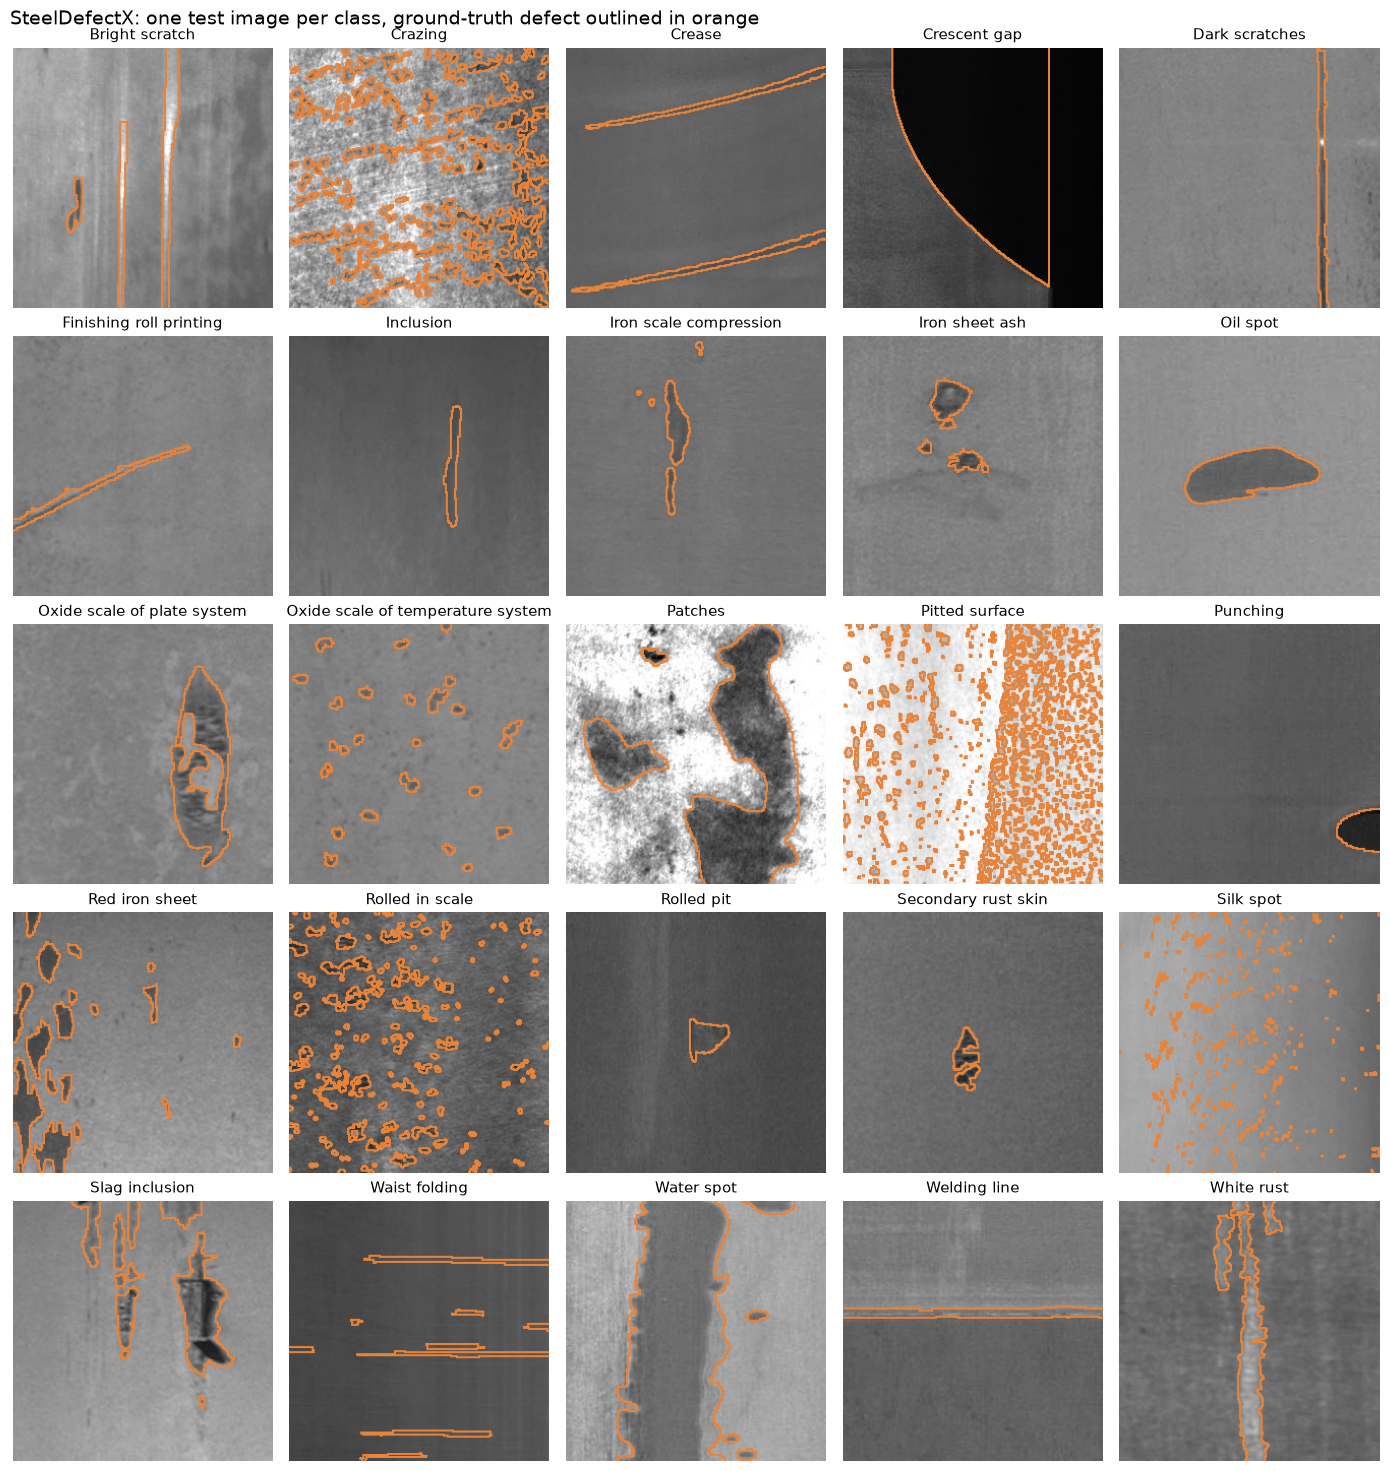

In [7]:
# Fig 3.1 — one test image per class with its ground-truth outline
pce = ROOT / "results" / "figures" / "per_class" / "per_class_examples.json"
picked = {e["class_name"]: e["image_name"] for e in json.load(open(pce))} if pce.exists() else {}
def pick(cls):
    if cls in picked and picked[cls] in name_to_class: return picked[cls]
    m = A["classes"] == cls                                   # fallback: median U-Net IoU in the class
    if not m.any(): return sorted(test_by_class[cls])[0]
    i = np.where(m)[0][np.argmin(np.abs(A["iou_unet"][m] - np.median(A["iou_unet"][m])))]
    return str(A["names"][i])

fig, axs = plt.subplots(5, 5, figsize=(14, 15))
for ax, cls in zip(axs.ravel(), sorted(test_by_class)):
    img, gt = load_pair(pick(cls))
    ax.imshow(gt_outline(img, gt)); ax.set_title(cls, fontsize=10.5); ax.axis("off")
fig.suptitle("SteelDefectX: one test image per class, ground-truth defect outlined in orange", x=0.01, ha="left", fontsize=14)
plt.tight_layout(); plt.savefig(OUT / "fig_dataset_grid_25.png"); plt.show()

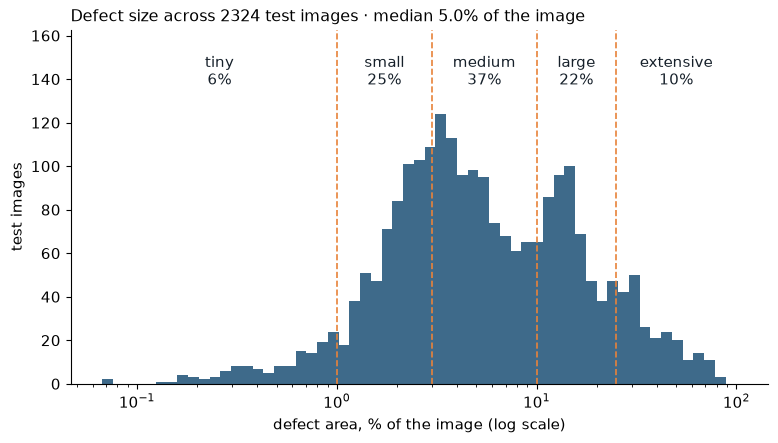

In [8]:
# Fig 3.3 — how big defects are: ground-truth area / image area, with the dataset's Scale buckets
area = A["gt_area"][A["gt_area"] > 0] * 100
cuts = [(0, 1, "tiny"), (1, 3, "small"), (3, 10, "medium"), (10, 25, "large"), (25, 101, "extensive")]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(area, bins=np.logspace(np.log10(max(area.min(), 0.01)), 2, 60), color=BLUE)
ax.set_xscale("log"); ax.set_xlabel("defect area, % of the image (log scale)"); ax.set_ylabel("test images")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)                                  # headroom for the bucket labels
for lo, hi, lab in cuts:
    if lo > 0: ax.axvline(lo, color=ORANGE, ls="--", lw=1.2)
    share = ((area >= lo) & (area < hi)).mean() * 100
    xm = np.sqrt(max(lo, area.min()) * min(hi, 100))
    ax.text(xm, ax.get_ylim()[1] * 0.93, f"{lab}\n{share:.0f}%", ha="center", va="top", fontsize=10.5, color=INK)
ax.set_title(f"Defect size across {len(area)} test images · median {np.median(area):.1f}% of the image", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(OUT / "fig_defect_area_hist.png"); plt.show()
summary["defect_area_median_pct"] = round(float(np.median(area)), 2)
summary["defect_area_share_below_10pct"] = round(float((area < 10).mean() * 100), 1)

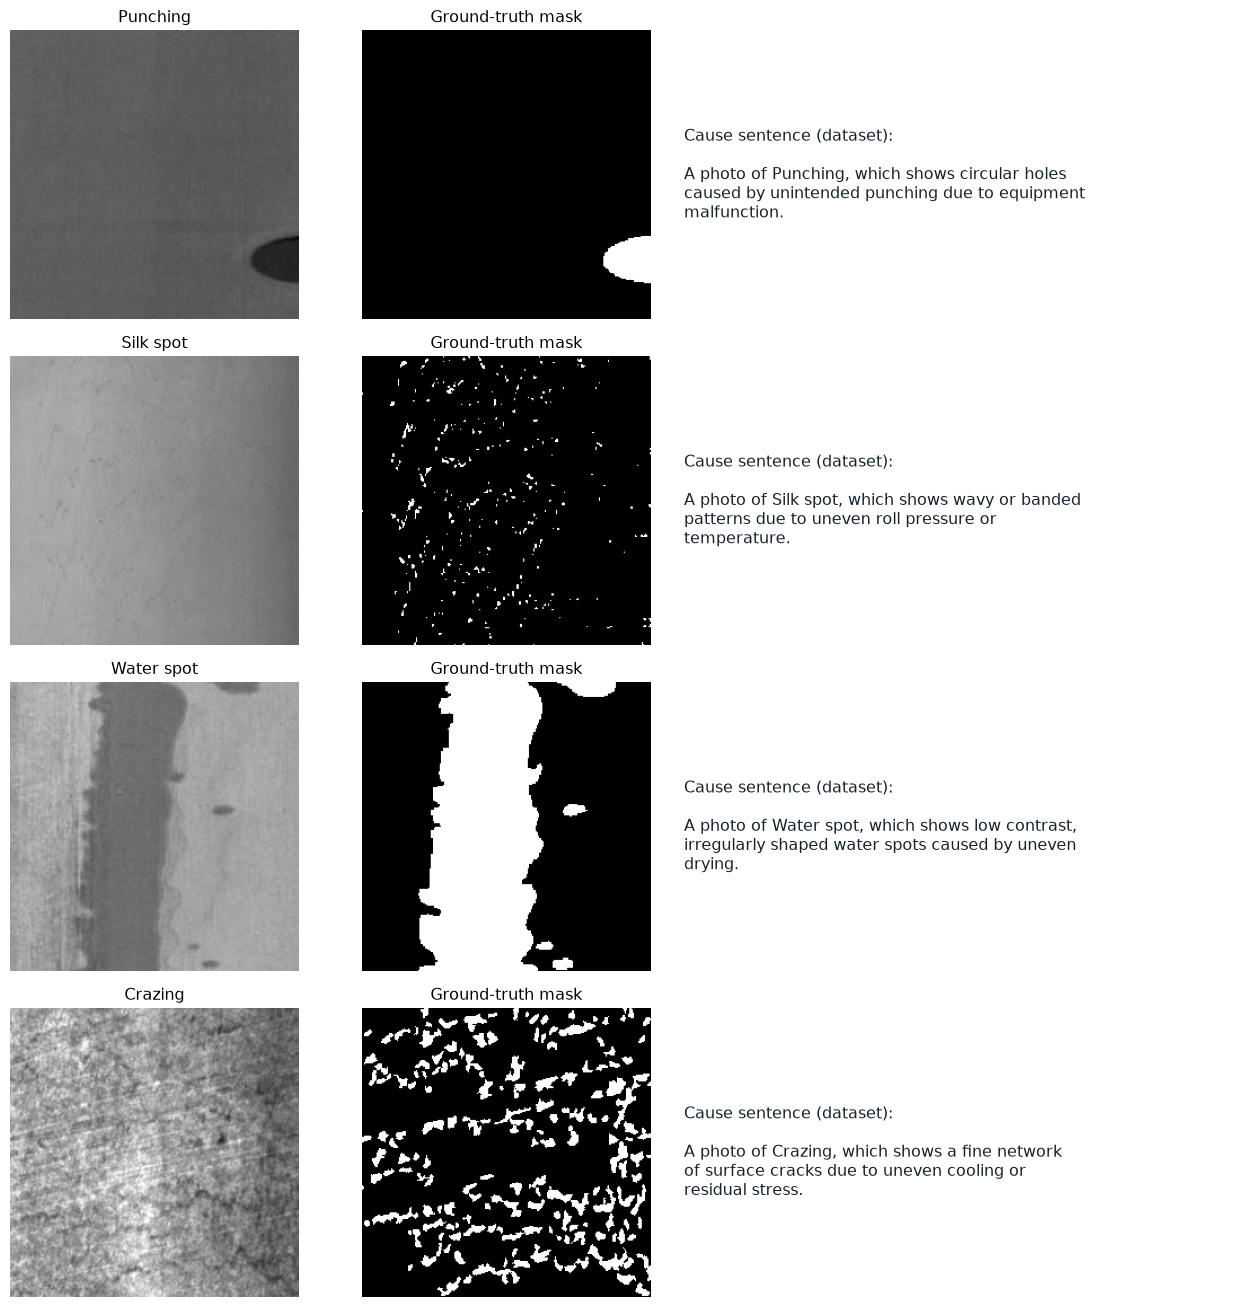

In [9]:
# Fig 3.5 — four classes with image, mask and the dataset's cause sentence
SAMPLE_CLASSES = ["Punching", "Silk spot", "Water spot", "Crazing"]
fig, axs = plt.subplots(len(SAMPLE_CLASSES), 3, figsize=(13, 3.3 * len(SAMPLE_CLASSES)),
                        gridspec_kw={"width_ratios": [1, 1, 1.6]})
for r, cls in enumerate(SAMPLE_CLASSES):
    img, gt = load_pair(pick(cls))
    show(axs[r, 0], img, cls); show(axs[r, 1], gt, "Ground-truth mask", "mask")
    axs[r, 2].axis("off")
    axs[r, 2].text(0, 0.5, "Cause sentence (dataset):\n\n" + textwrap.fill(cause_text(cls), 48),
                   va="center", fontsize=11.5, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_dataset_samples.png"); plt.show()

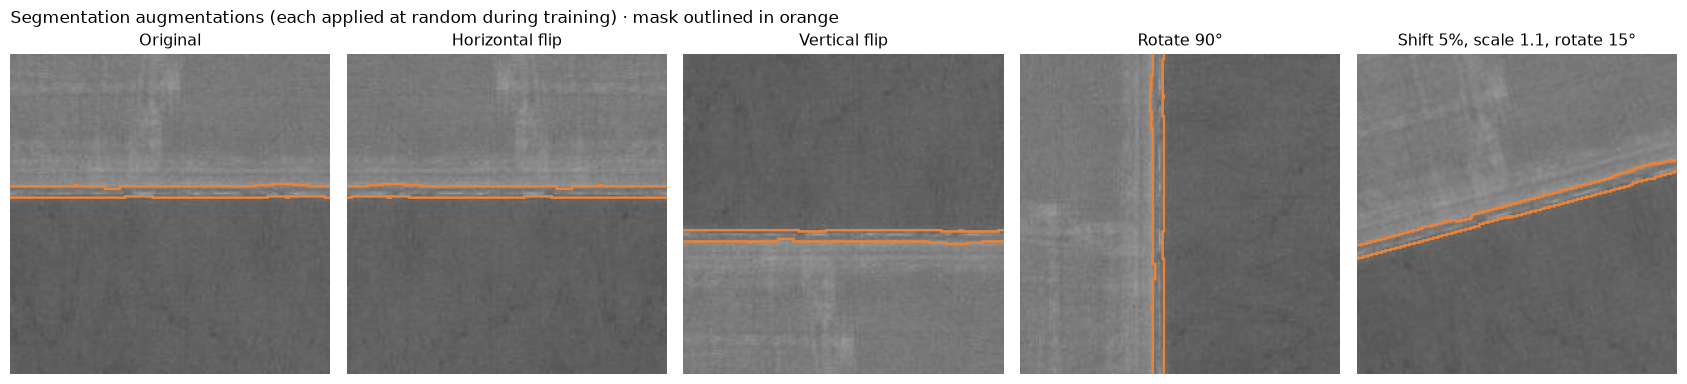

In [10]:
# Fig 3.6 — the segmentation training augmentations, each applied on its own (classifier uses horizontal flip only)
img, gt = load_pair(pick("Welding line"))
def ssr(a, interp):
    M = cv2.getRotationMatrix2D((128, 128), 15, 1.1); M[:, 2] += [0.05 * 256, 0.05 * 256]
    return cv2.warpAffine(a, M, (256, 256), flags=interp, borderMode=cv2.BORDER_REFLECT_101)
augs = [("Original", img, gt), ("Horizontal flip", img[:, ::-1], gt[:, ::-1]),
        ("Vertical flip", img[::-1], gt[::-1]), ("Rotate 90°", np.rot90(img).copy(), np.rot90(gt).copy()),
        ("Shift 5%, scale 1.1, rotate 15°", ssr(img, cv2.INTER_LINEAR), ssr(gt, cv2.INTER_NEAREST))]
fig, axs = plt.subplots(1, 5, figsize=(17, 3.9))
for ax, (t, a, m) in zip(axs, augs):
    ax.imshow(gt_outline(np.ascontiguousarray(a), np.ascontiguousarray(m))); ax.set_title(t); ax.axis("off")
fig.suptitle("Segmentation augmentations (each applied at random during training) · mask outlined in orange",
             x=0.01, ha="left", fontsize=12.5)
plt.tight_layout(); plt.savefig(OUT / "fig_augmentation_examples.png"); plt.show()

## 6. Method figure: from mask to attributes (report Fig 4.6) and the worked example (Fig 5.19)

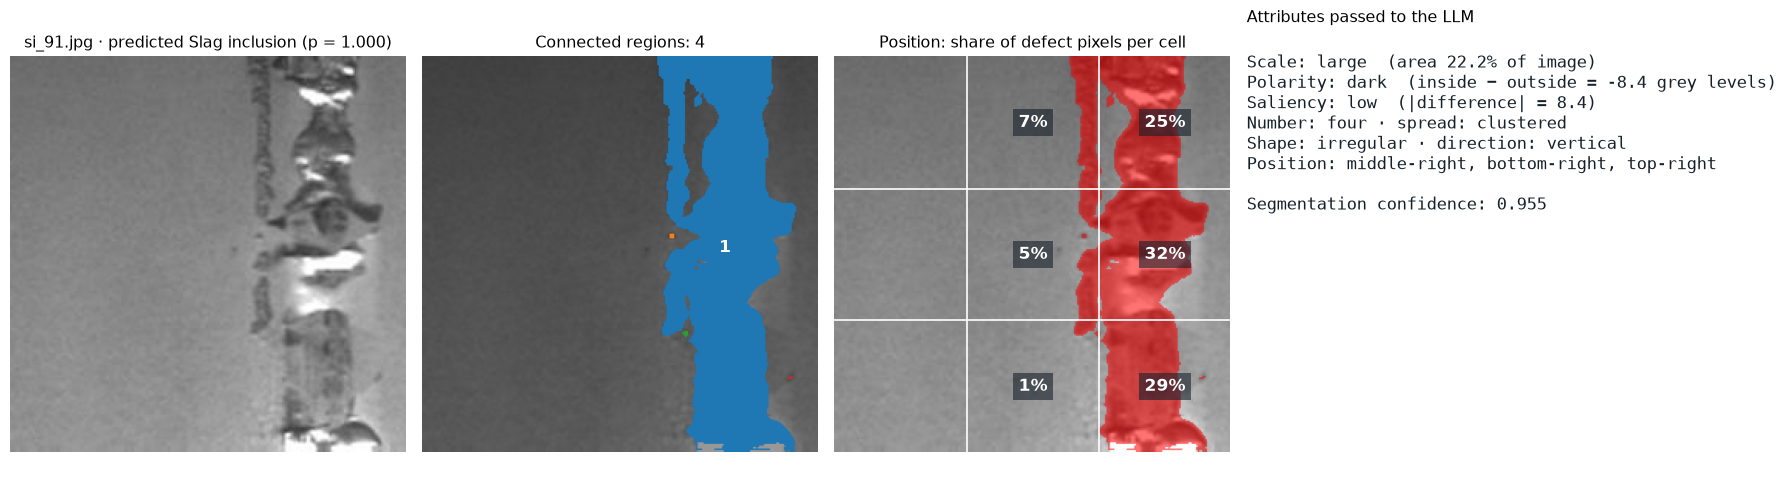

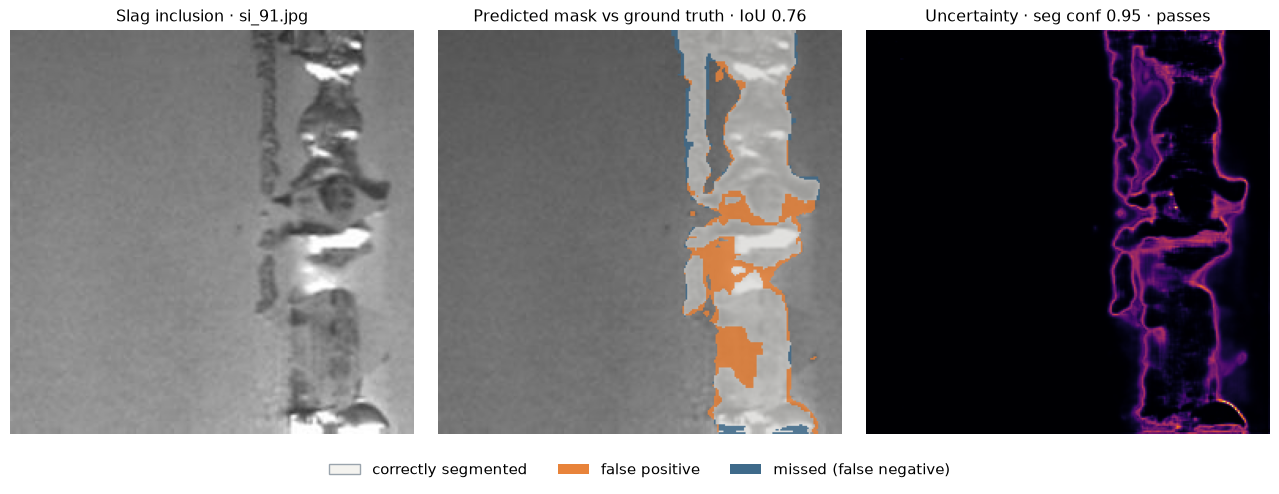

worked example: Slag inclusion 0.9997 | conf 0.955 | {'Shape': 'irregular', 'Direction': 'vertical', 'Spatial Distribution': 'clustered', 'Number of Defects': 'four', 'Position': [['middle-right', 0.320864], ['bottom-right', 0.291294], ['top-right', 0.250722], ['top-center', 0.073236], ['center', 0.054876], ['bottom-center', 0.009008]], 'Scale': 'large', 'Polarity': 'dark', 'Saliency': 'low'}


In [11]:
from src.llm.attributes import extract_attributes
img, gt = load_pair(WORKED_EXAMPLE)
prob, unc, conf = predict_mc(img)
probs = class_probs(img); pc = CLASS_NAMES[int(probs.argmax())]
attrs = extract_attributes(img, prob)
binary = (prob > 0.5).astype(np.uint8)
n_lab, labels, stats, cents = cv2.connectedComponentsWithStats(binary, connectivity=8)

fig, axs = plt.subplots(1, 4, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1, 1, 1.15]})
show(axs[0], img, f"{WORKED_EXAMPLE} · predicted {pc} (p = {probs.max():.3f})")
palette = plt.get_cmap("tab10")
comp = np.stack([img] * 3, -1).astype(np.float32) / 255 * 0.6
big = set(np.argsort(-stats[1:, cv2.CC_STAT_AREA])[:12] + 1)          # number only the 12 largest regions
for k in range(1, n_lab):
    comp[labels == k] = palette((k - 1) % 10)[:3]
    if k in big and stats[k, cv2.CC_STAT_AREA] >= 30:
        axs[1].text(cents[k][0], cents[k][1], str(k), color="white", fontsize=12, ha="center", va="center", weight="bold")
axs[1].imshow(comp); axs[1].set_title(f"Connected regions: {n_lab - 1}"); axs[1].axis("off")
axs[2].imshow(img, cmap="gray", vmin=0, vmax=255); axs[2].imshow(np.ma.masked_where(binary == 0, binary), cmap="autumn", alpha=0.55)
for t in (256 / 3, 512 / 3):
    axs[2].axhline(t, color="white", lw=1.2); axs[2].axvline(t, color="white", lw=1.2)
tot = binary.sum()
for gi in range(3):
    for gj in range(3):
        share = binary[gi * 256 // 3:(gi + 1) * 256 // 3, gj * 256 // 3:(gj + 1) * 256 // 3].sum() / max(tot, 1)
        if share > 0:
            axs[2].text((gj + 0.5) * 256 / 3, (gi + 0.5) * 256 / 3, f"{share * 100:.0f}%", color="white", ha="center",
                        va="center", fontsize=12, weight="bold", bbox=dict(facecolor=INK, alpha=0.6, lw=0))
axs[2].set_title("Position: share of defect pixels per cell"); axs[2].axis("off")
raw = attrs.get("_raw", {})
lines = [f"Scale: {attrs['Scale']}  (area {raw.get('area_ratio', 0) * 100:.1f}% of image)",
         f"Polarity: {attrs['Polarity']}  (inside − outside = {raw.get('polarity_diff', 0):+.1f} grey levels)",
         f"Saliency: {attrs['Saliency']}  (|difference| = {raw.get('saliency', 0):.1f})",
         f"Number: {attrs['Number of Defects']} · spread: {attrs['Spatial Distribution']}",
         f"Shape: {attrs['Shape']} · direction: {attrs['Direction']}",
         "Position: " + ", ".join(p for p, _ in attrs["Position"][:3]),
         "", f"Segmentation confidence: {conf:.3f}"]
axs[3].axis("off"); axs[3].set_title("Attributes passed to the LLM", loc="left")
axs[3].text(0, 0.95, "\n".join(lines), va="top", fontsize=12, color=INK, family="monospace")
plt.tight_layout(); plt.savefig(OUT / "fig_attribute_extraction.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
show(axs[0], img, f"{name_to_class[WORKED_EXAMPLE]} · {WORKED_EXAMPLE}")
show(axs[1], error_overlay(img, prob, gt), f"Predicted mask vs ground truth · IoU {iou(prob, gt):.2f}", "rgb")
axs[2].imshow(unc, cmap="inferno", vmin=0); axs[2].axis("off")
axs[2].set_title(f"Uncertainty · seg conf {conf:.2f} · " + ("passes" if conf >= REVIEW_CONFIDENCE_THRESHOLD else "flagged"))
fig.legend(handles=ERR_LEGEND, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(OUT / "fig_worked_example.png"); plt.show()
print("worked example:", pc, round(float(probs.max()), 4), "| conf", round(conf, 3), "|", {k: v for k, v in attrs.items() if k != "_raw"})

## 7. Classification results (report 5A)

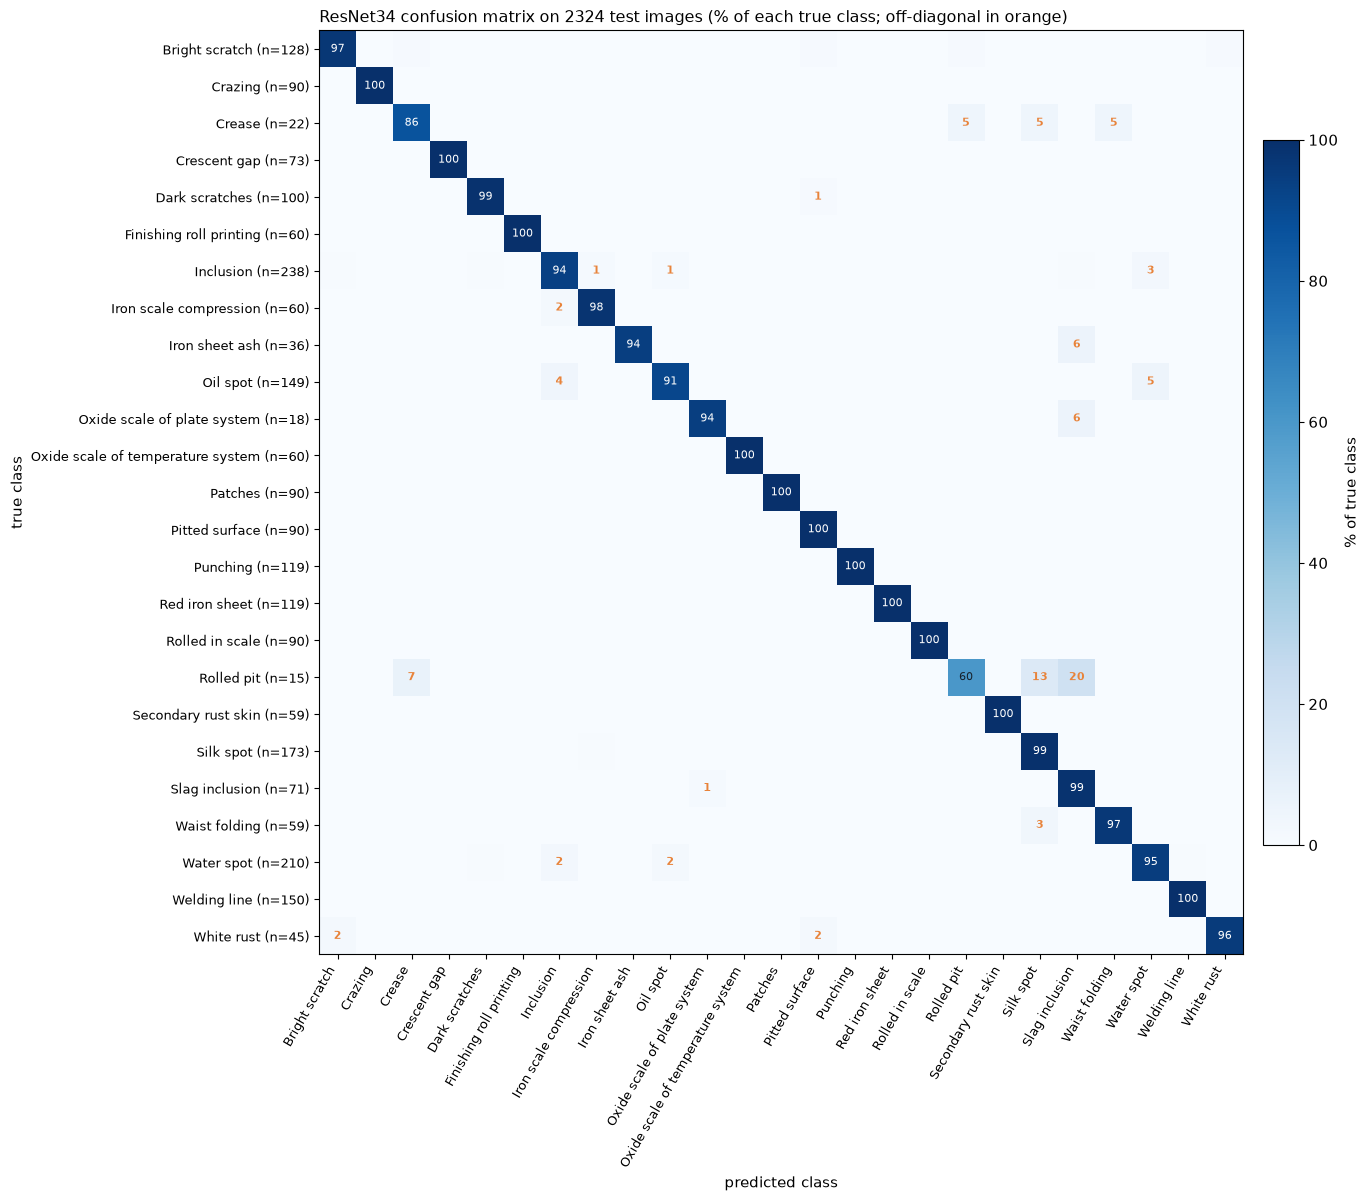

most confused (true -> predicted):
  Oil spot -> Water spot: 7
  Oil spot -> Inclusion: 6
  Inclusion -> Water spot: 6
  Water spot -> Inclusion: 5
  Water spot -> Oil spot: 4
  Rolled pit -> Slag inclusion: 3
  Inclusion -> Oil spot: 3
  Inclusion -> Iron scale compression: 3


[None, None, None, None, None, None, None, None]

In [12]:
# Fig 5.2 — row-normalised confusion matrix on the test set
cmat = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)))
for t, p in zip(y_true, y_pred): cmat[t, p] += 1
norm = cmat / np.maximum(cmat.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(norm * 100, cmap="Blues", vmin=0, vmax=100)
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if cmat[i, j] > 0 and (i == j or norm[i, j] >= 0.01):
            ax.text(j, i, f"{norm[i, j] * 100:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if norm[i, j] > 0.6 else (ORANGE if i != j else INK), weight="bold" if i != j else None)
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=60, ha="right", fontsize=9.5)
ax.set_yticks(range(len(CLASS_NAMES)), [f"{c} (n={int(cmat[i].sum())})" for i, c in enumerate(CLASS_NAMES)], fontsize=9.5)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
ax.set_title(f"ResNet34 confusion matrix on {int(cmat.sum())} test images (% of each true class; off-diagonal in orange)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="% of true class")
plt.savefig(OUT / "fig_confusion_matrix.png"); plt.show()
pairs = sorted(((int(cmat[i, j]), CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(len(CLASS_NAMES))
                for j in range(len(CLASS_NAMES)) if i != j and cmat[i, j] > 0), reverse=True)[:8]
summary["top_confused_pairs"] = [f"{a} -> {b}: {n}" for n, a, b in pairs]
print("most confused (true -> predicted):"); [print(" ", s) for s in summary["top_confused_pairs"]]

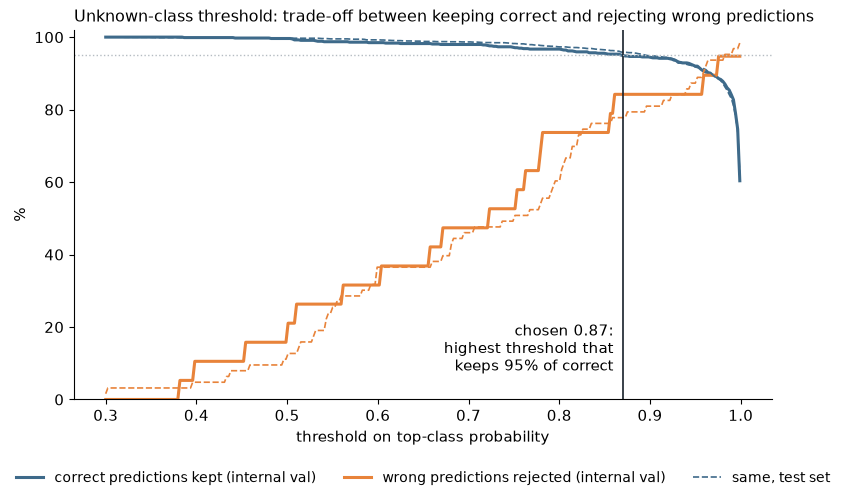

In [13]:
# Fig 5.4 — choosing the unknown-class threshold on internal validation (test shown dashed for reference)
th = np.linspace(0.3, 0.999, 300)
def curves(tp, ok):
    keep = np.array([(tp[ok] >= t).mean() * 100 for t in th])
    caught = np.array([(tp[~ok] < t).mean() * 100 if (~ok).any() else np.nan for t in th])
    return keep, caught
k_iv, c_iv = curves(B["top_p"], B["correct"].astype(bool))
k_te, c_te = curves(top_p, y_pred == y_true)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(th, k_iv, color=BLUE, lw=2.2, label="correct predictions kept (internal val)")
ax.plot(th, c_iv, color=ORANGE, lw=2.2, label="wrong predictions rejected (internal val)")
ax.plot(th, k_te, color=BLUE, lw=1.2, ls="--", label="same, test set")
ax.plot(th, c_te, color=ORANGE, lw=1.2, ls="--")
ax.axvline(UNKNOWN_THR, color=INK, lw=1.2); ax.axhline(95, color=GREY, lw=1, ls=":")
ax.text(UNKNOWN_THR - 0.01, 8, f"chosen {UNKNOWN_THR:.2f}:\nhighest threshold that\nkeeps 95% of correct", ha="right", fontsize=10.5)
ax.set_xlabel("threshold on top-class probability"); ax.set_ylabel("%"); ax.set_ylim(0, 102)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=10)
ax.set_title("Unknown-class threshold: trade-off between keeping correct and rejecting wrong predictions", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(OUT / "fig_unknown_threshold_curve.png"); plt.show()

## 8. Segmentation results (report 5B)

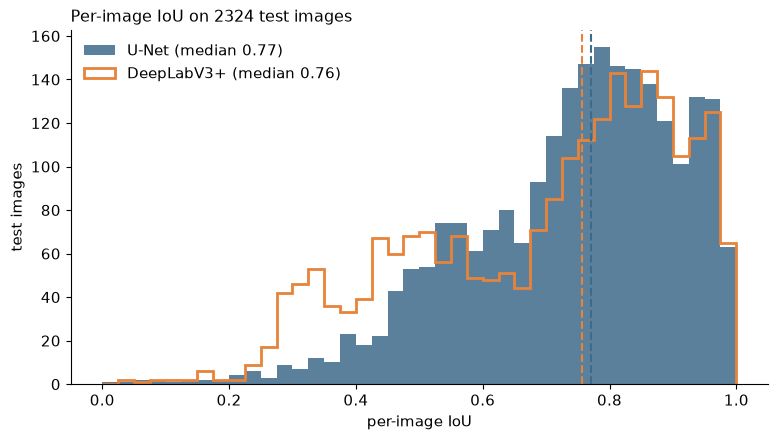

In [14]:
# Fig 5.8 — spread of per-image IoU, both models
fig, ax = plt.subplots(figsize=(9, 4.6))
b = np.linspace(0, 1, 41)
ax.hist(A["iou_unet"], b, color=BLUE, alpha=0.85, label=f"U-Net (median {np.median(A['iou_unet']):.2f})")
ax.hist(A["iou_dl"], b, histtype="step", color=ORANGE, lw=2, label=f"DeepLabV3+ (median {np.median(A['iou_dl']):.2f})")
ax.axvline(np.median(A["iou_unet"]), color=BLUE, ls="--"); ax.axvline(np.median(A["iou_dl"]), color=ORANGE, ls="--")
ax.set_xlabel("per-image IoU"); ax.set_ylabel("test images"); ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Per-image IoU on {len(A['iou_unet'])} test images", loc="left"); ax.spines[["top", "right"]].set_visible(False)
plt.savefig(OUT / "fig_image_iou_hist.png"); plt.show()
summary["unet_share_images_iou_below_0.5_pct"] = round(float((A["iou_unet"] < 0.5).mean() * 100), 1)

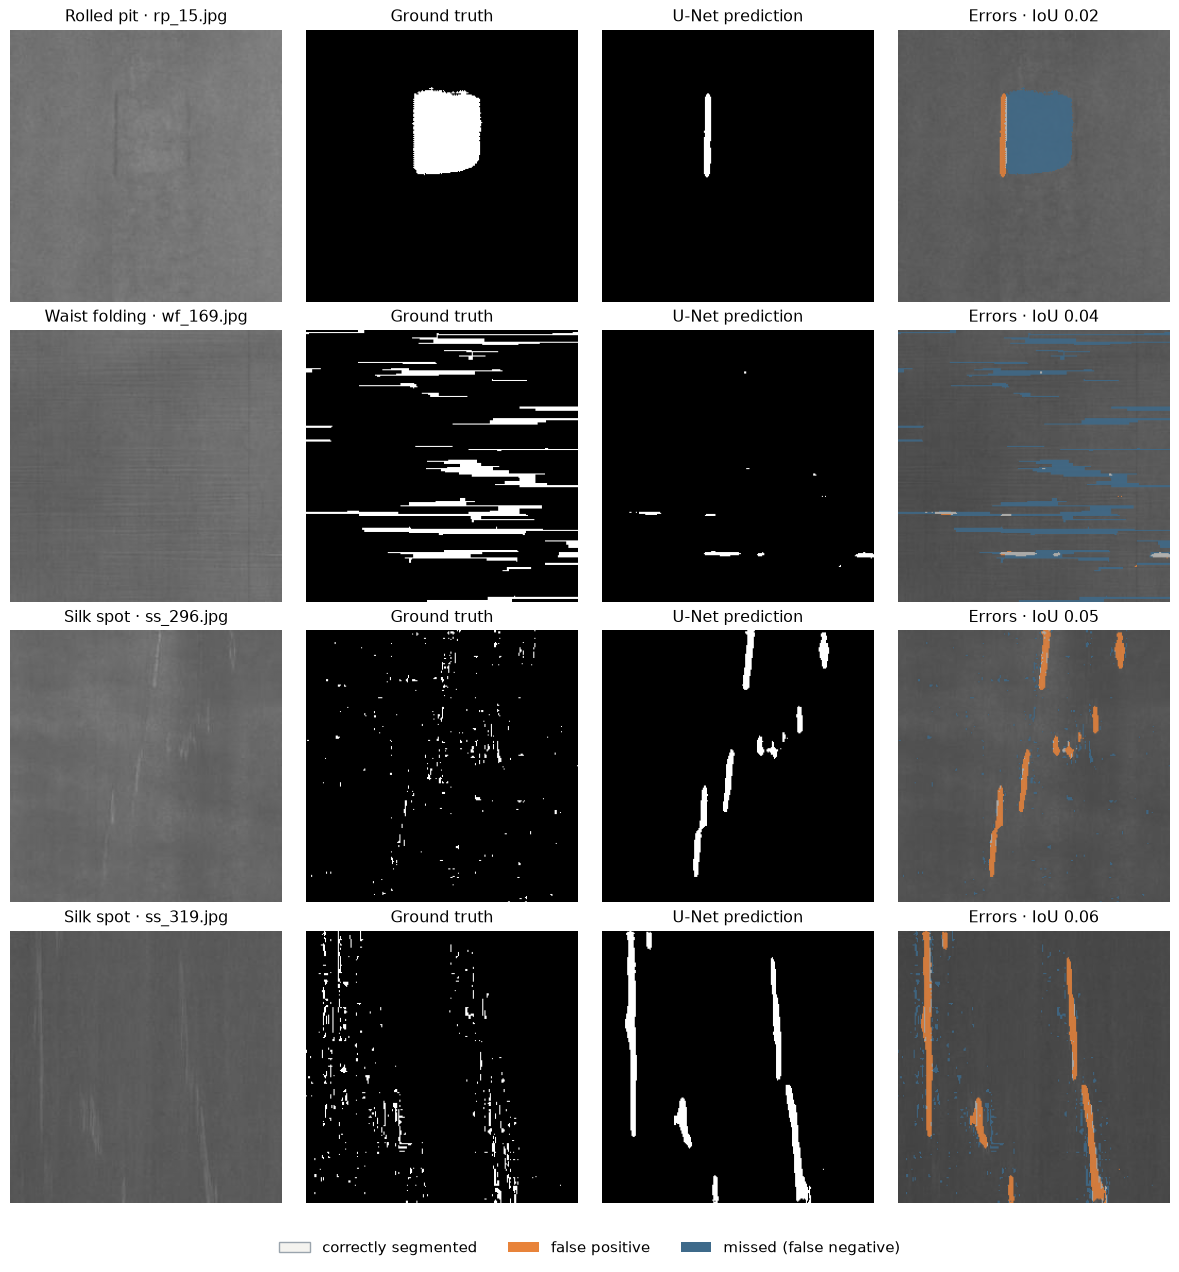

In [15]:
# Fig 5.11 — the four lowest-IoU test images (defect present), with error maps
has_defect = A["gt_area"] > 0
worst = np.where(has_defect)[0][np.argsort(A["iou_unet"][has_defect])[:4]]
fig, axs = plt.subplots(4, 4, figsize=(12, 12.6))
for r, i in enumerate(worst):
    nm = str(A["names"][i]); img, gt = load_pair(nm); pu = predict(unet, img)
    show(axs[r, 0], img, f"{A['classes'][i]} · {nm}"); show(axs[r, 1], gt, "Ground truth", "mask")
    show(axs[r, 2], pu > 0.5, "U-Net prediction", "mask")
    show(axs[r, 3], error_overlay(img, pu, gt), f"Errors · IoU {A['iou_unet'][i]:.2f}", "rgb")
fig.legend(handles=ERR_LEGEND, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(OUT / "fig_seg_failures.png"); plt.show()
summary["worst_images"] = [f"{A['names'][i]} ({A['classes'][i]}, IoU {A['iou_unet'][i]:.2f})" for i in worst]

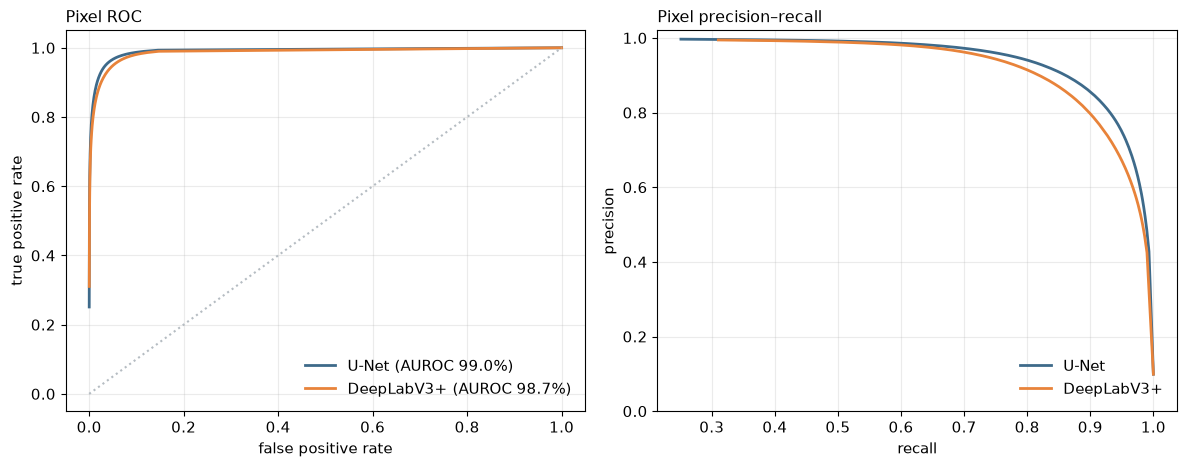

In [16]:
# Fig 5.12 — pixel-level ROC and precision-recall, from 1,000-bin histograms over all test pixels
def roc_pr(pos, neg):
    tp = np.cumsum(pos[::-1]); fp = np.cumsum(neg[::-1])          # thresholds from high to low
    tpr, fpr = tp / pos.sum(), fp / neg.sum()
    prec = tp / np.maximum(tp + fp, 1)
    auc = (np.trapezoid if hasattr(np, "trapezoid") else np.trapz)(np.r_[0, tpr], np.r_[0, fpr])
    return fpr, tpr, prec, auc
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.8))
for key, lab, col in (("unet", "U-Net", BLUE), ("dl", "DeepLabV3+", ORANGE)):
    fpr, tpr, prec, auc = roc_pr(A[f"{key}_pos"], A[f"{key}_neg"])
    a.plot(fpr, tpr, color=col, lw=2, label=f"{lab} (AUROC {auc * 100:.1f}%)")
    b.plot(tpr, prec, color=col, lw=2, label=lab)
    summary[f"{key}_pixel_auroc_hist"] = round(float(auc * 100), 2)
a.plot([0, 1], [0, 1], ":", color=GREY); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate")
b.set_xlabel("recall"); b.set_ylabel("precision"); b.set_ylim(0, 1.02)
a.set_title("Pixel ROC", loc="left"); b.set_title("Pixel precision–recall", loc="left")
for ax in (a, b): ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(OUT / "fig_pixel_roc_pr.png"); plt.show()

## 9. Is the uncertainty useful? (report 5C)

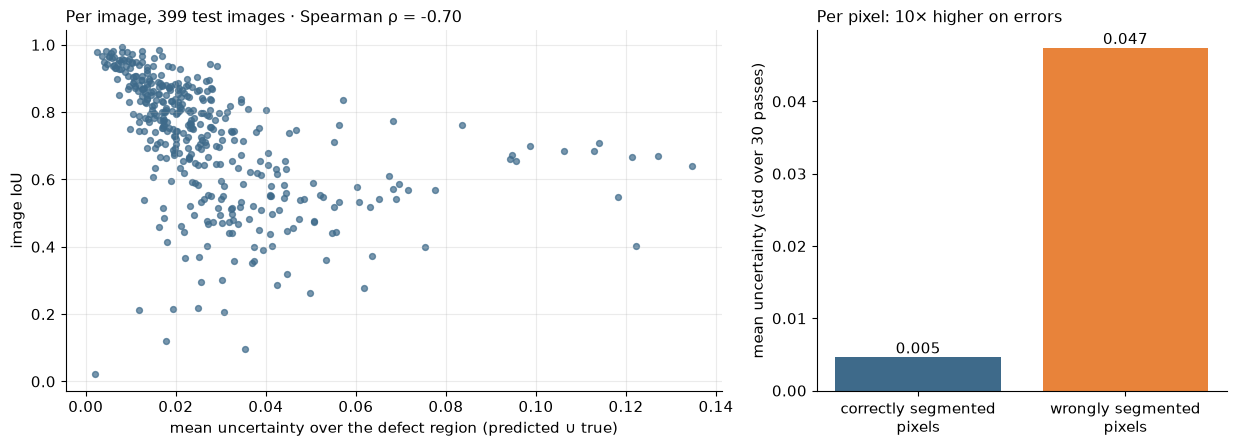

In [17]:
# Fig 5.15 — uncertainty vs error
def spearman(x, y):
    rx, ry = np.argsort(np.argsort(x)), np.argsort(np.argsort(y))
    return float(np.corrcoef(rx, ry)[0, 1])
rho = spearman(C["unc_defect"], C["iou"])
fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
a.scatter(C["unc_defect"], C["iou"], s=18, color=BLUE, alpha=0.7)
a.set_xlabel("mean uncertainty over the defect region (predicted ∪ true)"); a.set_ylabel("image IoU")
a.set_title(f"Per image, {len(C['iou'])} test images · Spearman ρ = {rho:.2f}", loc="left"); a.grid(alpha=0.25)
vals = [float(C["unc_pix_correct"]), float(C["unc_pix_wrong"])]
b.bar(["correctly segmented\npixels", "wrongly segmented\npixels"], vals, color=[BLUE, ORANGE])
for i, v in enumerate(vals): b.text(i, v, f"{v:.3f}", ha="center", va="bottom")
b.set_ylabel("mean uncertainty (std over 30 passes)"); b.set_title(f"Per pixel: {vals[1] / max(vals[0], 1e-9):.0f}× higher on errors", loc="left")
for ax in (a, b): ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "fig_uncertainty_vs_error.png"); plt.show()
summary["uncertainty_iou_spearman"] = round(rho, 3)
summary["uncertainty_ratio_wrong_vs_correct_pixels"] = round(vals[1] / max(vals[0], 1e-9), 1)

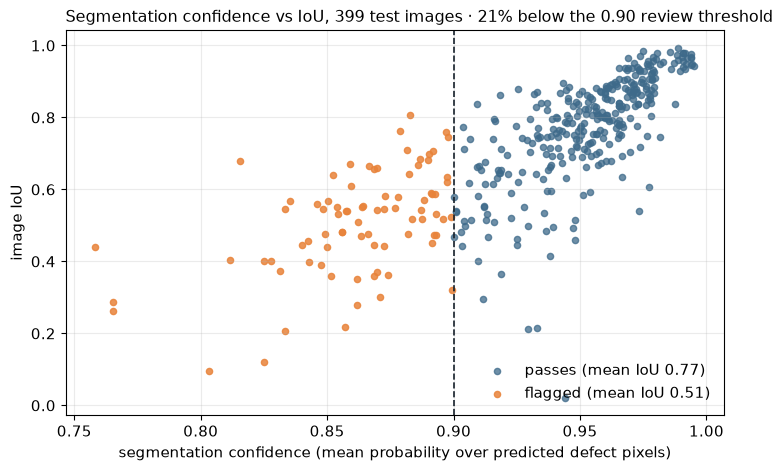

In [18]:
# Fig 5.16 — segmentation confidence vs IoU, with the 0.90 review threshold
flag = C["conf"] < REVIEW_CONFIDENCE_THRESHOLD
fig, ax = plt.subplots(figsize=(8.5, 5))
mean_or_nan = lambda a: float(a.mean()) if len(a) else float("nan")
ax.scatter(C["conf"][~flag], C["iou"][~flag], s=20, color=BLUE, alpha=0.75, label=f"passes (mean IoU {mean_or_nan(C['iou'][~flag]):.2f})")
ax.scatter(C["conf"][flag], C["iou"][flag], s=20, color=ORANGE, alpha=0.85, label=f"flagged (mean IoU {mean_or_nan(C['iou'][flag]):.2f})")
ax.axvline(REVIEW_CONFIDENCE_THRESHOLD, color=INK, ls="--", lw=1.2)
ax.set_xlabel("segmentation confidence (mean probability over predicted defect pixels)"); ax.set_ylabel("image IoU")
ax.set_title(f"Segmentation confidence vs IoU, {len(C['conf'])} test images · {flag.mean() * 100:.0f}% below the 0.90 review threshold", loc="left")
ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.25)
plt.savefig(OUT / "fig_confidence_vs_iou.png"); plt.show()
summary["mc_subset_n"] = int(len(C["conf"]))
summary["mean_iou_passed"] = round(float(C["iou"][~flag].mean()), 3) if (~flag).any() else None
summary["mean_iou_flagged"] = round(float(C["iou"][flag].mean()), 3) if flag.any() else None

In [19]:
json.dump(summary, open(OUT / "report_figures_summary.json", "w"), indent=1)
print(json.dumps(summary, indent=1))
print("\nfigures in", OUT)
for f in sorted(OUT.glob("*.png")): print(" ", f.name)

{
 "test_n": 2324,
 "test_accuracy_pct": 97.29,
 "unet_mean_image_iou": 74.08,
 "deeplab_mean_image_iou": 70.06,
 "defect_area_median_pct": 4.97,
 "defect_area_share_below_10pct": 67.9,
 "top_confused_pairs": [
  "Oil spot -> Water spot: 7",
  "Oil spot -> Inclusion: 6",
  "Inclusion -> Water spot: 6",
  "Water spot -> Inclusion: 5",
  "Water spot -> Oil spot: 4",
  "Rolled pit -> Slag inclusion: 3",
  "Inclusion -> Oil spot: 3",
  "Inclusion -> Iron scale compression: 3"
 ],
 "unet_share_images_iou_below_0.5_pct": 9.6,
 "worst_images": [
  "rp_15.jpg (Rolled pit, IoU 0.02)",
  "wf_169.jpg (Waist folding, IoU 0.04)",
  "ss_296.jpg (Silk spot, IoU 0.05)",
  "ss_319.jpg (Silk spot, IoU 0.06)"
 ],
 "unet_pixel_auroc_hist": 99.03,
 "dl_pixel_auroc_hist": 98.67,
 "uncertainty_iou_spearman": -0.695,
 "uncertainty_ratio_wrong_vs_correct_pixels": 10.2,
 "mc_subset_n": 399,
 "mean_iou_passed": 0.775,
 "mean_iou_flagged": 0.509
}

figures in /Users/debarshinimondal/Desktop/BTP/SteelDefectX/resul